# Cluster Effects Preprocessing

**EmbeddingGemma 2 version** of `main/code/02_cluster_centroid_products.ipynb`: the fine-tuned (DoubleMLDeep) product embeddings are replaced by [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) embeddings (text + image, Matryoshka 256 dimensions; the text-only embeddings are EmbeddingGemma 2 text-only embeddings, also with 256 dimensions). Datasets are read from `gemma/data`, raw data from `main/data`, outputs are written to `gemma/outputs`.

In [1]:
import os
import datasets
import pandas as pd
import numpy as np
import lightning.pytorch as pl

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import textwrap
from IPython.display import display  # Import display function

import doubleml as dml
from doubleml.utils import DMLDummyRegressor

from sklearn.cluster import KMeans
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, pairwise_distances
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from lightgbm import LGBMRegressor
from utils.utils_gemma import load_embeddings
from utils.utils_data2 import (
    load_pred_and_emb,
    center_and_norm,
    get_pca,
    get_cluster,
    get_similarities,
    add_lags_and_scale_data,
)

confidence_level = 0.9
ci_level_name = f"{round((confidence_level) * 100, 1)}%"
ci_names = [
    f"{round((1 - confidence_level) * 100 / 2, 1)}%",
    f"{round((1 + confidence_level) * 100 / 2, 1)}%",
]
print(ci_level_name)
print(ci_names)

90.0%
['5.0%', '95.0%']


## Set Output Directory

In [2]:
output_dir = "../outputs/02_cluster_centroid_products"
Path(output_dir).mkdir(parents=True, exist_ok=True)


## Data Loading and Preprocessing

In [3]:
txt_only = False
include_embeddings = True
dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
df_full_train = pd.read_csv(f"../data/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"../data/{dataframe_name}_val.zip")

columns_to_drop = []

df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

data_files = {
    "train": [f"train-0000{i}-of-00004-part00{j}.parquet" for i in range(4) for j in range(4)],
}

ds_img = datasets.load_dataset(
    "parquet",
    data_dir="../../main/data/amzn_toys_monthly_avg_long_ffill_28_7_images",
    data_files=data_files,
)

df_img = ds_img["train"].to_pandas()

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 500 examples [00:01, 305.40 examples/s]

Generating train split: 1100 examples [00:03, 343.21 examples/s]

Generating train split: 1700 examples [00:04, 415.07 examples/s]

...

Generating train split: 7910 examples [00:11, 934.33 examples/s]

Generating train split: 8710 examples [00:12, 769.89 examples/s]

Generating train split: 9410 examples [00:13, 690.71 examples/s]

Generating train split: 9613 examples [00:14, 669.77 examples/s]

Generating train split: 9613 examples [00:14, 671.12 examples/s]

In [4]:
# text-only embeddings: EmbeddingGemma 2 (text only, Matryoshka 256 dimensions)
# instead of the time-independent fine-tuned text-only model
emb_txt = load_embeddings("../data/embeddings/embeddinggemma2_txt.parquet", emb_dim=256)
print(f"Text-only embeddings: {emb_txt.shape}")

Text-only embeddings: (7549, 256)


In [5]:
# product-level embeddings broadcast to the (ASIN, date) panel
train_emb_txt = emb_txt.loc[df_full_train["ASIN"]].set_axis(
    pd.MultiIndex.from_frame(df_full_train[["ASIN", "date"]])
)
val_emb_txt = emb_txt.loc[df_full_val["ASIN"]].set_axis(
    pd.MultiIndex.from_frame(df_full_val[["ASIN", "date"]])
)

train_emb_txt.columns = [f"{x}_txt" for x in train_emb_txt.columns]
val_emb_txt.columns = [f"{x}_txt" for x in val_emb_txt.columns]

df_full_train = df_full_train.set_index(["ASIN", "date"]).join(train_emb_txt)
df_full_val = df_full_val.set_index(["ASIN", "date"]).join(val_emb_txt)

In [6]:
columns = [
    "ASIN",
    "Q_t",
    "P_bb_t",
    "text",
    "date",
    "window",
    "REVIEW_COUNT",
    "RATING",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
    "Lightning Deals: Upcoming Deal",
    "Buy Box: Is FBA",
    "subcat_aggregated",
]

# Clustering

In [7]:
emb_columns = ["ASIN", "date"] + [f"emb_{i}" for i in range(256)]
emb_columns_txt = ["ASIN", "date"] + [f"emb_{i}_txt" for i in range(256)]

In [8]:
full_embeddings_txtimg = center_and_norm(
    df_full_train.reset_index()[emb_columns], df_full_val.reset_index()[emb_columns]
)

full_embeddings_txtimg.shape

(68766, 256)

In [9]:
full_embeddings_txt = center_and_norm(
    df_full_train.reset_index()[emb_columns_txt],
    df_full_val.reset_index()[emb_columns_txt],
)

full_embeddings_txt.shape

(68766, 256)

In [10]:
kmeans_txt_labels, cluster_centroids_txt = get_cluster(
    full_embeddings_txt, n_clusters=5
)
kmeans_txtimg_labels, cluster_centroids_txtimg = get_cluster(
    full_embeddings_txtimg, n_clusters=5
)

## PCA Visualization

In [11]:
pca_img = PCA(n_components=2, random_state=42)
pca_img_results = pca_img.fit_transform(full_embeddings_txtimg)

pca_txt = PCA(n_components=2, random_state=42)
pca_txt_results = pca_txt.fit_transform(full_embeddings_txt)

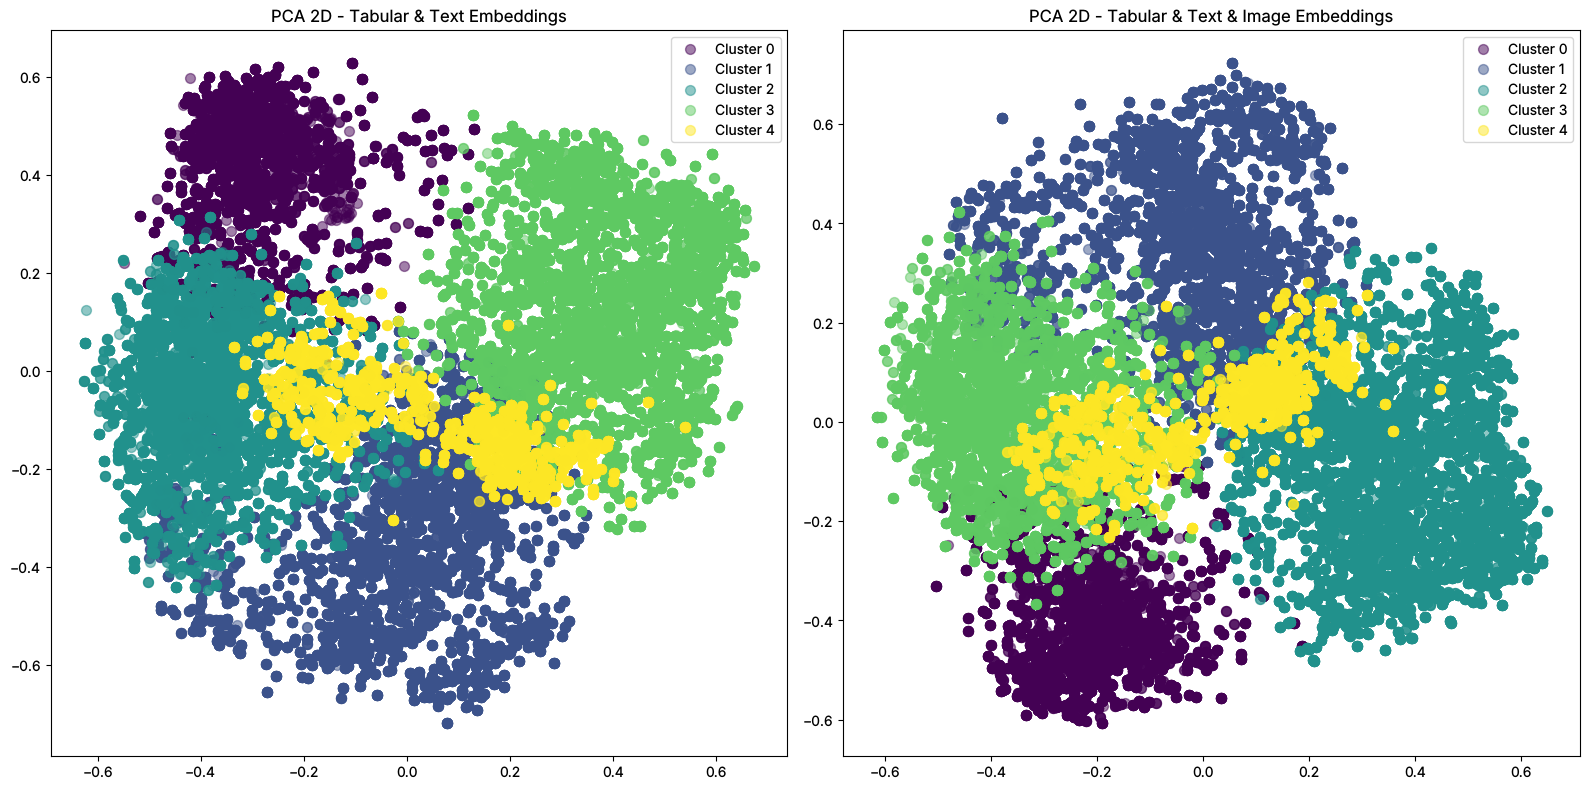

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot for text embeddings
unique_cluster_ids = np.unique(kmeans_txt_labels)
colors = cm.viridis(np.linspace(0, 1, len(unique_cluster_ids)))

for i, cluster_id in enumerate(unique_cluster_ids):
    axes[0].scatter(
        pca_txt_results[kmeans_txt_labels == cluster_id, 0],
        pca_txt_results[kmeans_txt_labels == cluster_id, 1],
        color=colors[i],
        label=f"Cluster {cluster_id}",
        s=50,
        alpha=0.5,
    )
axes[0].set_title("PCA 2D - Tabular & Text Embeddings")
axes[0].legend()

# Plot for image embeddings
unique_cluster_ids = np.unique(kmeans_txtimg_labels)

for i, cluster_id in enumerate(unique_cluster_ids):
    axes[1].scatter(
        pca_img_results[kmeans_txtimg_labels == cluster_id, 0],
        pca_img_results[kmeans_txtimg_labels == cluster_id, 1],
        color=colors[i],
        label=f"Cluster {cluster_id}",
        s=50,
        alpha=0.5,
    )
axes[1].set_title("PCA 2D - Tabular & Text & Image Embeddings")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "pca_2d_clusters.png"))
plt.show()

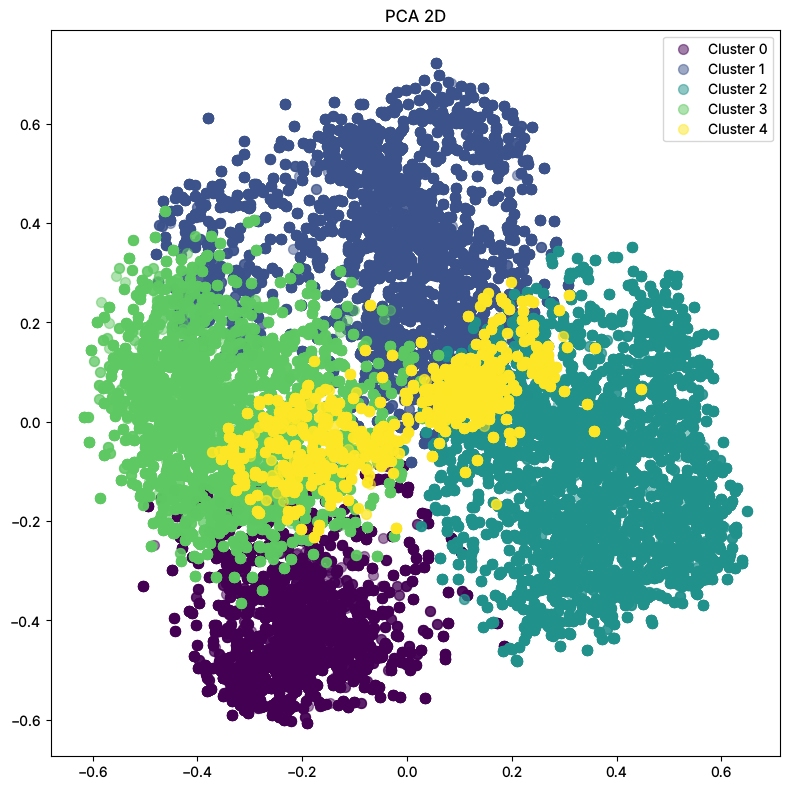

In [13]:
fig = plt.figure(figsize=(8, 8))
unique_cluster_ids = np.unique(kmeans_txtimg_labels)
colors = cm.viridis(np.linspace(0, 1, len(unique_cluster_ids)))

for i, cluster_id in enumerate(unique_cluster_ids):
    plt.scatter(
        pca_img_results[kmeans_txtimg_labels == cluster_id, 0],
        pca_img_results[kmeans_txtimg_labels == cluster_id, 1],
        color=colors[i],
        label=f"Cluster {cluster_id}",
        s=50,
        alpha=0.5,
    )
plt.title("PCA 2D")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "pca_img_clusters.png"))
plt.show()

## 3D PCA Visualization

In [14]:
pca_img_3d = PCA(n_components=3, random_state=42)
pca_img_3d_results = pca_img_3d.fit_transform(full_embeddings_txtimg)

pca_txt_3d = PCA(n_components=3, random_state=42)
pca_txt_3d_results = pca_txt_3d.fit_transform(full_embeddings_txt)

In [15]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import matplotlib.colors as mcolors  # To convert colors to hex

colors = [
    mcolors.rgb2hex(cm.viridis(i)) for i in np.linspace(0, 1, len(unique_cluster_ids))
]

fig = make_subplots(rows=1, cols=1, specs=[[{"type": "scatter3d"}]])


# Convert index to row and column in a 2x2 grid
row, col = divmod(0, 1)

# Create traces for each cluster
for i, cluster_id in enumerate(unique_cluster_ids):
    mask = kmeans_txtimg_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_img_3d_results[mask, 0],  # PC1
            y=pca_img_3d_results[mask, 1],  # PC2
            z=pca_img_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors[i], opacity=0.075),
            name=f"Cluster {cluster_id}",
        ),
        row=row + 1,
        col=col + 1,
    )

# Step 5: Set titles and layout
fig.update_layout(
    height=800,
    width=800,
    template="none",
    margin=dict(t=5, r=20, b=10, l=20),
    scene=dict(
        xaxis=dict(range=[-1, 1]),
        yaxis=dict(range=[-1, 1]),
        zaxis=dict(range=[-1, 1]),
        camera_eye=dict(x=1, y=2, z=1),
    ),
)

fig.update_layout(
    legend=dict(
        x=0.5,  # Center the legend horizontally
        y=-0.01,  # Place the legend below the plot
        xanchor="center",  # Align legend horizontally by its center
        yanchor="top",  # Align legend vertically by its top
        orientation="h",  # Arrange legend items horizontally
        bgcolor="rgba(255, 255, 255, 0.7)",  # Optional: Add a semi-transparent background
        bordercolor="black",  # Optional: Add a border
        borderwidth=1,  # Optional: Set border width
    )
)

# Step 6: Show plot
fig.show()
fig.write_image(os.path.join(output_dir, "3d_embedding_txtimg.png"))

In [16]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import matplotlib.colors as mcolors  # To convert colors to hex

colors = [
    mcolors.rgb2hex(cm.viridis(i)) for i in np.linspace(0, 1, len(unique_cluster_ids))
]

fig = make_subplots(rows=1, cols=1, specs=[[{"type": "scatter3d"}]])


# Convert index to row and column in a 2x2 grid
row, col = divmod(0, 1)


# Create traces for each cluster
for i, cluster_id in enumerate(unique_cluster_ids):
    mask = kmeans_txt_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_txt_3d_results[mask, 0],  # PC1
            y=pca_txt_3d_results[mask, 1],  # PC2
            z=pca_txt_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors[i], opacity=0.075),
            name=f"Cluster {cluster_id}",
        ),
        row=row + 1,
        col=col + 1,
    )

# Step 5: Set titles and layout
fig.update_layout(
    height=800,
    width=800,
    template="none",
    margin=dict(t=5, r=20, b=10, l=20),
    scene=dict(
        xaxis=dict(range=[-1, 1]),
        yaxis=dict(range=[-1, 1]),
        zaxis=dict(range=[-1, 1]),
        camera_eye=dict(x=1, y=2, z=1),
    ),
)

fig.update_layout(
    legend=dict(
        x=0.5,  # Center the legend horizontally
        y=-0.01,  # Place the legend below the plot
        xanchor="center",  # Align legend horizontally by its center
        yanchor="top",  # Align legend vertically by its top
        orientation="h",  # Arrange legend items horizontally
        bgcolor="rgba(255, 255, 255, 0.7)",  # Optional: Add a semi-transparent background
        bordercolor="black",  # Optional: Add a border
        borderwidth=1,  # Optional: Set border width
    )
)

# Step 6: Show plot
fig.show()
fig.write_image(os.path.join(output_dir, "3d_embedding_txt.png"))

In [17]:
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import matplotlib.colors as mcolors  # To convert colors to hex

# Assuming pca_img_3d_results and pca_txt_3d_results are already computed
unique_cluster_ids_img = np.unique(kmeans_txtimg_labels)
unique_cluster_ids_txt = np.unique(kmeans_txt_labels)

colors_img = [
    mcolors.rgb2hex(cm.viridis(i))
    for i in np.linspace(0, 1, len(unique_cluster_ids_img))
]
colors_txt = [
    mcolors.rgb2hex(cm.viridis(i))
    for i in np.linspace(0, 1, len(unique_cluster_ids_txt))
]

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}]],
    subplot_titles=(
        "Tabular & Text Embeddings",
        "Tabular & Text & Image Embeddings",
    ),  # Add subplot titles
)

# Create traces for each cluster for text embeddings
for i, cluster_id in enumerate(unique_cluster_ids_txt):
    mask = kmeans_txt_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_txt_3d_results[mask, 0],  # PC1
            y=pca_txt_3d_results[mask, 1],  # PC2
            z=pca_txt_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors_txt[i], opacity=0.3),
            name=f"Cluster {cluster_id}",
            showlegend=True,  # Show legend only for the first subplot
        ),
        row=1,
        col=1,
    )

# Create traces for each cluster for image embeddings
for i, cluster_id in enumerate(unique_cluster_ids_img):
    mask = kmeans_txtimg_labels == cluster_id
    fig.add_trace(
        go.Scatter3d(
            x=pca_img_3d_results[mask, 0],  # PC1
            y=pca_img_3d_results[mask, 1],  # PC2
            z=pca_img_3d_results[mask, 2],  # PC3
            mode="markers",
            marker=dict(size=5, color=colors_img[i], opacity=0.3),
            name=f"Cluster {cluster_id}",
            showlegend=False,  # Hide legend for the second subplot
        ),
        row=1,
        col=2,
    )

# Set titles and layout with camera angles
fig.update_layout(
    height=600,
    width=900,  # Adjusted figure size
    title_text="PCA 3D Cluster Visualization",
    scene_camera=dict(
        eye=dict(
            x=1.25, y=1.25, z=1.25
        )  # Adjust the camera angle for the first subplot
    ),
    scene2_camera=dict(
        eye=dict(
            x=1.25, y=1.25, z=1.25
        )  # Adjust the camera angle for the second subplot
    ),
)

# Show plot
fig.show()

In [18]:
df_full = pd.concat([df_full_train, df_full_val]).reset_index()

In [19]:
df_full

,ASIN,date,index,Q_t,PRICE,P_bb_t,text,window,REVIEW_COUNT,RATING,...,emb_246_txt,emb_247_txt,emb_248_txt,emb_249_txt,emb_250_txt,emb_251_txt,emb_252_txt,emb_253_txt,emb_254_txt,emb_255_txt
0,1947335162,2023-03-27,17,-12.515369,3.427422,3.633271,Catalyst Game Labs Battletech: Technical Reado...,28.0,62.035714,4.678571,...,0.039945,0.024382,-0.021701,-0.012537,0.030088,-0.042193,0.016427,-0.015303,-0.028013,-0.031299
1,1947335162,2023-04-24,25,-12.576837,3.400864,3.582963,Catalyst Game Labs Battletech: Technical Reado...,28.0,63.607143,4.700000,...,0.039945,0.024382,-0.021701,-0.012537,0.030088,-0.042193,0.016427,-0.015303,-0.028013,-0.031299
2,1947335162,2023-05-22,33,-12.688608,3.400864,3.587493,Catalyst Game Labs Battletech: Technical Reado...,28.0,64.000000,4.700000,...,0.039945,0.024382,-0.021701,-0.012537,0.030088,-0.042193,0.016427,-0.015303,-0.028013,-0.031299
3,1947335162,2023-06-19,41,-12.238366,3.400864,3.555062,Catalyst Game Labs Battletech: Technical Reado...,28.0,64.892857,4.700000,...,0.039945,0.024382,-0.021701,-0.012537,0.030088,-0.042193,0.016427,-0.015303,-0.028013,-0.031299
4,1947335162,2023-07-17,49,-12.362335,3.400864,3.539400,Catalyst Game Labs Battletech: Technical Reado...,28.0,65.000000,4.700000,...,0.039945,0.024382,-0.021701,-0.012537,0.030088,-0.042193,0.016427,-0.015303,-0.028013,-0.031299
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68761,B0CMLQYL7H,2024-01-29,585573,-12.426648,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Mack Truck NO.64 & ...,28.0,4.000000,4.150000,...,-0.000431,-0.060320,-0.007454,-0.072384,0.018010,-0.008703,0.003619,-0.019216,-0.018958,-0.065490
68762,B0CMLQZVT7,2024-01-29,585729,-12.379784,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Truck NO.117 Ralph ...,28.0,4.000000,4.150000,...,-0.009894,-0.066766,-0.020391,-0.065734,0.002043,-0.030286,-0.000578,-0.032523,-0.013594,-0.052312
68763,B0CMLS8KNB,2024-01-29,585885,-12.079333,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Truck NO.28 & Phil ...,28.0,4.000000,4.150000,...,-0.014160,-0.066023,-0.015029,-0.077491,0.018156,-0.022934,-0.000462,-0.019633,-0.013900,-0.066023
68764,B0CMLSH3M2,2024-01-29,586041,-12.567084,2.771964,2.771964,wltk Movie Cars 2 3 Hauler Truck NO.82 Darren ...,28.0,4.000000,4.150000,...,-0.012781,-0.062179,-0.009197,-0.071160,0.022281,-0.029535,-0.001447,-0.019776,-0.010579,-0.066324


In [20]:
n_clusters = 5

centroids_img = cluster_centroids_txtimg
cl_img = [f"similarity_cluster_img_{i}" for i in range(n_clusters)]

centroids_txt = cluster_centroids_txt
cl_txt = [f"similarity_cluster_txt_{i}" for i in range(n_clusters)]
df_full_val.loc[:, cl_txt] = np.nan
df_full_train.loc[:, cl_txt] = np.nan
df_full.loc[:, cl_txt] = np.nan

In [21]:
from sklearn.metrics import pairwise_distances

for i_embedding, embedding in enumerate(full_embeddings_txtimg.values):
    for i, centroid in enumerate(centroids_img):
        similarity = 1.0 - pairwise_distances(
            embedding.reshape(1, -1), centroid.reshape(1, -1), metric="cosine"
        )
        df_full.loc[i_embedding, cl_img[i]] = similarity

for i_embedding, embedding in enumerate(full_embeddings_txt.values):
    for i, centroid in enumerate(centroids_txt):
        similarity = 1.0 - pairwise_distances(
            embedding.reshape(1, -1), centroid.reshape(1, -1), metric="cosine"
        )
        df_full.loc[i_embedding, cl_txt[i]] = similarity

In [22]:
n_neighbors = 4
closest_points_img = [None]
closest_points_indices_val_img = None
for embeddings, centroids, val_cluster_ids in zip(
    [full_embeddings_txtimg], [centroids_img], [kmeans_txtimg_labels]
):
    for i_embedding, embedding in enumerate([embeddings]):
        distances = pairwise_distances(embedding, centroids, metric="euclidean")
        closest_points_indices = []
        for i in range(n_clusters):
            cluster_indices = np.where(val_cluster_ids == i)[0]
            cluster_distances = distances[cluster_indices, i]
            sorted_indices = cluster_indices[np.argsort(cluster_distances)]

            closest_indices_i = []
            seen_asins = set()

            for idx in sorted_indices:
                asin = df_full.loc[idx, "ASIN"]
                if asin not in seen_asins:
                    closest_indices_i.append(idx)
                    seen_asins.add(asin)
                if len(closest_indices_i) == n_neighbors:
                    break

            closest_points_indices.append(closest_indices_i)

        closest_points_img[i_embedding] = closest_points_indices
    closest_points_indices_val = closest_points_img

closest_points_txt = [None]
closest_points_indices_val_txt = None
for embeddings, centroids, val_cluster_ids in zip(
    [full_embeddings_txt], [centroids_txt], [kmeans_txt_labels]
):
    for i_embedding, embedding in enumerate([embeddings]):
        distances = pairwise_distances(embedding, centroids, metric="euclidean")
        closest_points_indices = []
        for i in range(n_clusters):
            cluster_indices = np.where(val_cluster_ids == i)[0]
            cluster_distances = distances[cluster_indices, i]
            sorted_indices = cluster_indices[np.argsort(cluster_distances)]

            closest_indices_i = []
            seen_asins = set()

            for idx in sorted_indices:
                asin = df_full.loc[idx, "ASIN"]
                if asin not in seen_asins:
                    closest_indices_i.append(idx)
                    seen_asins.add(asin)
                if len(closest_indices_i) == n_neighbors:
                    break

            closest_points_indices.append(closest_indices_i)

        closest_points_txt[i_embedding] = closest_points_indices
    closest_points_indices_val_txt = closest_points_txt

In [23]:
import os
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import textwrap
from IPython.display import display  # Remove if not using Jupyter Notebook

# Ensure output directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

text_len = 45
try:
    font = ImageFont.truetype("arial.ttf", 22)
    font = ImageFont.truetype("arialbd.ttf", size=36)
except IOError:
    font = ImageFont.load_default()

In [24]:
from PIL import ImageFont
from datasets import Image as dsImage
from PIL import Image

data_files = {
    "train": ["train-00000-of-00002.parquet", "train-00001-of-00002.parquet"],
    "validation": [
        "validation-00000-of-00002.parquet",
        "validation-00001-of-00002.parquet",
    ],
}


ds_dict = datasets.load_dataset(
    "parquet",
    data_dir="../../main/data/amzn_toys_monthly_diffs_ffill_fixed_splits_buybox",
    data_files=data_files,
)

ds_full = datasets.concatenate_datasets(
    [ds_dict["train"], ds_dict["validation"]]
)

ds_full = ds_full.to_pandas().set_index("ASIN")

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 1000 examples [00:00, 2027.85 examples/s]

Generating train split: 28000 examples [00:00, 61625.04 examples/s]

Generating train split: 62000 examples [00:00, 127978.32 examples/s]

Generating train split: 96000 examples [00:00, 180623.23 examples/s]

...

Generating validation split: 563478 examples [00:12, 42716.21 examples/s]

Generating validation split: 571478 examples [00:12, 47628.20 examples/s]

Generating validation split: 580478 examples [00:12, 57102.55 examples/s]

Generating validation split: 588478 examples [00:12, 59110.81 examples/s]

Generating validation split: 592956 examples [00:12, 47462.68 examples/s]

In [25]:
df_img = df_img.set_index("ASIN")

In [26]:
import io

for i, indices in enumerate(closest_points_img[0]):
    print(f"Cluster {i}:")
    images = []
    for idx in indices:
        asin = df_full.loc[int(idx), "ASIN"]
        try:
            text = ds_full.loc[asin, "text"][0]
        except KeyError:
            print(f"Index {idx} not found in DataFrame.")
            continue

        truncated_text = (text[:text_len] + "...") if len(text) > text_len else text
        img = Image.open(io.BytesIO(df_img.loc[asin, :].values[0]["bytes"]))

        # Adjust image size
        img = img.resize((600, 400))  # Adjust the size as needed

        # Create a new canvas for the image and text
        unit_width = 600
        unit_height = 550  # Adjust height to accommodate text
        unit_canvas = Image.new(
            "RGB", (unit_width, unit_height), color=(255, 255, 255)
        )  # White background

        # Paste the image onto the canvas
        unit_canvas.paste(img, (0, 0))

        # Draw text below the image
        draw = ImageDraw.Draw(unit_canvas)

        lines = textwrap.wrap(truncated_text, width=30)
        ascent, descent = font.getmetrics()
        line_height = ascent + descent
        y_text = img.height + 10  # Start just below the image

        for line in lines:
            draw.text((10, y_text), line, font=font, fill=(0, 0, 0))  # Black text
            y_text += line_height

        images.append(unit_canvas)

    if not images:
        print(f"No images found for Cluster {i}.")
        continue

    # Adjust the collage dimensions
    num_images = len(images)
    grid_columns = 4  # Adjust based on desired layout
    grid_rows = int(np.ceil(num_images / grid_columns))
    collage_width = unit_width * grid_columns
    collage_height = unit_height * grid_rows

    collage = Image.new(
        "RGB", (collage_width, collage_height), color=(255, 255, 255)
    )  # White background

    # Place each unit onto the collage
    for idx, img in enumerate(images):
        x = (idx % grid_columns) * unit_width
        y = (idx // grid_columns) * unit_height
        collage.paste(img, (x, y))

    # Display or save the collage
    # If using Jupyter Notebook, you can use display(collage)
    collage.show()
    collage.save(os.path.join(output_dir, f"collage_cluster_img_{i}.png"))
    print(f"Collage for Cluster (img) {i} saved successfully.\n" + "-" * 50 + "\n")

Cluster 0:


/tmp/ipykernel_7780/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpsnzr_970.PNG'
/tmp/ipykernel_7780/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (img) 0 saved successfully.
--------------------------------------------------

Cluster 1:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpwrof9b4m.PNG'
/tmp/ipykernel_7780/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



...

/tmp/ipykernel_7780/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpc0ta5bhc.PNG'
/tmp/ipykernel_7780/3193574232.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (img) 3 saved successfully.
--------------------------------------------------

Cluster 4:


Collage for Cluster (img) 4 saved successfully.
--------------------------------------------------



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmph6iqkz9f.PNG'


In [27]:
# Assuming df, ds, and closest_points are already defined
for i, indices in enumerate(closest_points_txt[0]):
    print(f"Cluster {i}:")
    images = []
    for idx in indices:
        asin = df_full.loc[int(idx), "ASIN"]
        try:
            text = ds_full.loc[asin, "text"][0]
        except KeyError:
            print(f"Index {idx} not found in DataFrame.")
            continue

        truncated_text = (text[:text_len] + "...") if len(text) > text_len else text
        img = Image.open(io.BytesIO(df_img.loc[asin, :].values[0]["bytes"]))

        # Adjust image size
        img = img.resize((600, 400))  # Adjust the size as needed

        # Create a new canvas for the image and text
        unit_width = 600
        unit_height = 550  # Adjust height to accommodate text
        unit_canvas = Image.new(
            "RGB", (unit_width, unit_height), color=(255, 255, 255)
        )  # White background

        # Paste the image onto the canvas
        unit_canvas.paste(img, (0, 0))

        # Draw text below the image
        draw = ImageDraw.Draw(unit_canvas)

        lines = textwrap.wrap(truncated_text, width=30)
        ascent, descent = font.getmetrics()
        line_height = ascent + descent
        y_text = img.height + 10  # Start just below the image

        for line in lines:
            draw.text((10, y_text), line, font=font, fill=(0, 0, 0))  # Black text
            y_text += line_height

        images.append(unit_canvas)

    if not images:
        print(f"No images found for Cluster {i}.")
        continue

    # Adjust the collage dimensions
    num_images = len(images)
    grid_columns = 4  # Adjust based on desired layout
    grid_rows = int(np.ceil(num_images / grid_columns))
    collage_width = unit_width * grid_columns
    collage_height = unit_height * grid_rows

    collage = Image.new(
        "RGB", (collage_width, collage_height), color=(255, 255, 255)
    )  # White background

    # Place each unit onto the collage
    for idx, img in enumerate(images):
        x = (idx % grid_columns) * unit_width
        y = (idx // grid_columns) * unit_height
        collage.paste(img, (x, y))

    # Display or save the collage
    # If using Jupyter Notebook, you can use display(collage)
    collage.show()
    collage.save(os.path.join(output_dir, f"collage_cluster_txt_{i}.png"))
    print(f"Collage for Cluster (txt) {i} saved successfully.\n" + "-" * 50 + "\n")

/tmp/ipykernel_7780/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Cluster 0:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpnvy_st8j.PNG'
/tmp/ipykernel_7780/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (txt) 0 saved successfully.
--------------------------------------------------

Cluster 1:


/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmp0lacmyls.PNG'
/tmp/ipykernel_7780/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



...

/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpr_dh01mc.PNG'


Collage for Cluster (txt) 3 saved successfully.
--------------------------------------------------

Cluster 4:


/tmp/ipykernel_7780/586051905.py:8: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Collage for Cluster (txt) 4 saved successfully.
--------------------------------------------------



/usr/bin/xdg-open: 882: www-browser: not found
/usr/bin/xdg-open: 882: links2: not found
/usr/bin/xdg-open: 882: elinks: not found
/usr/bin/xdg-open: 882: links: not found
/usr/bin/xdg-open: 882: lynx: not found
/usr/bin/xdg-open: 882: w3m: not found
xdg-open: no method available for opening '/tmp/tmpjws_gci_.PNG'


In [28]:
all_texts_img = {}

for i, indices in enumerate(closest_points_img[0]):
    print(f"Cluster {i}:")
    all_texts_img[i] = []
    for i_idx, idx in enumerate(indices):
        asin = df_full.loc[int(idx), "ASIN"]
        print(f"Closest point {i_idx}:")
        text = ds_full.loc[asin, "text"][0]
        all_texts_img[i].append(text)
        truncated_text = (text[:70] + "...") if len(text) > 50 else text
        print(truncated_text)
    print("\n" + "-" * 50 + "\n")

/tmp/ipykernel_7780/1257881989.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Cluster 0:
Closest point 0:
Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...
Closest point 1:
Diecast Toy Car Model 3 Car Model,Zinc Alloy Simulation Casting Tesla ...
Closest point 2:
Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...
Closest point 3:
Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...

--------------------------------------------------

Cluster 1:
Closest point 0:
Thomas & Friends Wooden Railway Toy Train Set Knapford Station Passeng...
Closest point 1:
Thomas & Friends Toy Train, Wobble Cargo Thomas Motorized Engine with ...
Closest point 2:


Thomas and Friends Big Loader — Motorized Thomas the Train Set — Inclu...
Closest point 3:
Melissa & Doug 17-Piece Wooden Take-Along Tabletop Railroad, 3 Trains,...

--------------------------------------------------

Cluster 2:
Closest point 0:


Hot Wheels #725 Race Team Series IV '67 Camaro | Cars & Race Cars | '6...
Closest point 1:
Hot Wheels Custom Ford Maverick, Muscle Mania 2/10 | Cars & Race Cars ...
Closest point 2:
Hot Wheels Fast and Furious 5-Pack of Toy Cars in 1:64 Scale, Replicas...
Closest point 3:
Hot Wheels Premium 2023 Car Culture Canyon Warriors '89 Porsche 944 Tu...

--------------------------------------------------

Cluster 3:
Closest point 0:
Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
Closest point 1:
Construction Truck Toys - 4 Pack Excavator, Mixer, Crane, Dump Trucks ...
Closest point 2:
Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
Closest point 3:


Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...

--------------------------------------------------

Cluster 4:
Closest point 0:
Prolific Complete Fingerboard with Upgraded Components - Pro Board Sha...
Closest point 1:


Teak Tuning Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape...
Closest point 2:
Premium Wooden Fingerboard Deck, Poolparty Cruiser Shape - 33.5mm x 94...
Closest point 3:
Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape - "Cherry R...

--------------------------------------------------



## Products closest to the centroids of the clusters used in `04_evaluation.ipynb`

The clusters above are re-estimated in this notebook (k-means with `n_init=10` on the estimation sample). `04_evaluation.ipynb` and `02_cluster_summary.ipynb` use the clusters of `01_1_create_dataset_txt_img.ipynb` (`similarity_cluster_*`, k-means with `n_init=200` on the full panel), whose numbering and composition need not coincide with the clusters above (see the cross-tabulation at the end of the notebook). The headlines below are therefore generated from the 4 products closest to the centroids of the `similarity_cluster_*` clusters (largest cosine similarity among the products assigned to the cluster).

In [29]:
sim_cols = [f"similarity_cluster_{i}" for i in range(n_clusters)]
df_full["similarity_cluster"] = df_full[sim_cols].values.argmax(axis=1)

all_texts_similarity_cluster = {}
closest_asins_similarity_cluster = {}
for k in range(n_clusters):
    members = df_full[df_full["similarity_cluster"] == k].sort_values(sim_cols[k], ascending=False)
    members = members.drop_duplicates("ASIN").head(n_neighbors)
    closest_asins_similarity_cluster[k] = members["ASIN"].tolist()
    all_texts_similarity_cluster[k] = members["text"].tolist()
    print(f"similarity_cluster_{k} ({df_full.loc[df_full['similarity_cluster'] == k, 'ASIN'].nunique()} products):")
    for text in all_texts_similarity_cluster[k]:
        print("   ", (text[:70] + "...") if len(text) > 50 else text)

similarity_cluster_0 (1682 products):
    Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
    Construction Truck Toys - 4 Pack Excavator, Mixer, Crane, Dump Trucks ...
    Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
    Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...


similarity_cluster_1 (1974 products):
    Hot Wheels Fast and Furious 5-Pack of Toy Cars in 1:64 Scale, Replicas...
    Hot Wheels Custom Ford Maverick, Muscle Mania 2/10 | Cars & Race Cars ...
    Hot Wheels #725 Race Team Series IV '67 Camaro | Cars & Race Cars | '6...
    Hot Wheels The Mystery Machine Vehicle | Cars & Race Cars | Hot Wheels...
similarity_cluster_2 (753 products):
    Prolific Complete Fingerboard with Upgraded Components - Pro Board Sha...
    Premium Wooden Fingerboard Deck, Poolparty Cruiser Shape - 33.5mm x 94...
    Teak Tuning Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape...
    Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape - "Cherry R...


similarity_cluster_3 (1512 products):
    Thomas & Friends Wooden Railway Toy Train Set Knapford Station Passeng...
    Thomas & Friends Toy Train, Wobble Cargo Thomas Motorized Engine with ...
    Thomas and Friends Big Loader — Motorized Thomas the Train Set — Inclu...
    Melissa & Doug 17-Piece Wooden Take-Along Tabletop Railroad, 3 Trains,...
similarity_cluster_4 (1305 products):
    Diecast Toy Car Model 3 Car Model,Zinc Alloy Simulation Casting Tesla ...
    Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...
    Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...
    Movie Car Toys Car 1:55 Diecast Vehicles for Kids Boys | Cars & Race C...


In [30]:
for k, asins in closest_asins_similarity_cluster.items():
    images = []
    for asin in asins:
        text = df_full.loc[df_full["ASIN"] == asin, "text"].iloc[0]
        truncated_text = (text[:text_len] + "...") if len(text) > text_len else text
        img = Image.open(io.BytesIO(df_img.loc[asin, :].values[0]["bytes"])).resize((600, 400))
        unit_canvas = Image.new("RGB", (unit_width, unit_height), color=(255, 255, 255))
        unit_canvas.paste(img, (0, 0))
        draw = ImageDraw.Draw(unit_canvas)
        ascent, descent = font.getmetrics()
        y_text = img.height + 10
        for line in textwrap.wrap(truncated_text, width=30):
            draw.text((10, y_text), line, font=font, fill=(0, 0, 0))
            y_text += ascent + descent
        images.append(unit_canvas)
    collage = Image.new("RGB", (unit_width * len(images), unit_height), color=(255, 255, 255))
    for i_img, img in enumerate(images):
        collage.paste(img, (i_img * unit_width, 0))
    collage.save(os.path.join(output_dir, f"collage_similarity_cluster_{k}.png"))
    print(f"Collage for similarity_cluster_{k} saved successfully.")

Collage for similarity_cluster_0 saved successfully.


Collage for similarity_cluster_1 saved successfully.


Collage for similarity_cluster_2 saved successfully.


Collage for similarity_cluster_3 saved successfully.


Collage for similarity_cluster_4 saved successfully.



# Workflow Cluster Headline Generation

**Model used:** Claude (Anthropic). The original analysis used Google Gemini 3 Pro, which was not available in the environment used for this replication.

The headlines refer to the clusters `similarity_cluster_0`, ..., `similarity_cluster_4` used in `04_evaluation.ipynb` and `02_cluster_summary.ipynb`; the input are the 4 products closest to their centroids (`all_texts_similarity_cluster`, see above). The short labels used in `02_cluster_summary.ipynb` are condensed versions of the headlines.

## Input

**Prompt used:** *I have applied k-means clustering to product data, resulting in 5 distinct clusters. For each cluster, I have a list of the 4 product descriptions closest to its centroid. Using these descriptions, please generate a clear, concise, and descriptive headline for each cluster that encapsulates the overarching theme, key features, or common characteristics shared by the products. The goal is to create informative and generalizable headlines that could apply to the group as a whole. The headline should generalize the product characteristics to verbally depict the typical attributes found in the cluster, without displaying any explicit brands or violating content policies. Here are the product descriptions for the 4 closest products in each cluster:* <all_texts_similarity_cluster>

## Output

Cluster 0

Toddler Friction-Powered Construction Truck Multi-Pack Playsets

Cluster 1

1:64 Scale Die-Cast Collectible Muscle and Movie Car Replicas

Cluster 2

Premium Handmade Wooden Fingerboard Decks and Complete Setups

Cluster 3

Preschool Wooden and Motorized Character Train Railway Playsets

Cluster 4

Mid-Scale Alloy Pull-Back Car Models with Lights and Sound

**Short labels:** 0: Toddler Construction Trucks; 1: 1:64 Die-Cast Collectibles; 2: Wooden Fingerboards; 3: Toy Train Playsets; 4: Light & Sound Pull-Back Cars

# Workflow Cluster Image Generation

Not reproduced for the EmbeddingGemma 2 clusters: no image-generation model was available in the environment used for this replication (the original analysis used Google Gemini 3 Pro + Nano Banana Pro with the prompt given in `main/code/02_cluster_centroid_products.ipynb`).

In [31]:
all_texts_txt = {}

for i, indices in enumerate(closest_points_txt[0]):
    print(f"Cluster {i}:")
    all_texts_txt[i] = []
    for i_idx, idx in enumerate(indices):
        asin = df_full.loc[int(idx), "ASIN"]
        print(f"Closest point {i_idx}:")
        text = ds_full.loc[asin, "text"][0]
        all_texts_txt[i].append(text)
        truncated_text = (text[:70] + "...") if len(text) > 50 else text
        print(truncated_text)
    print("\n" + "-" * 50 + "\n")

Cluster 0:
Closest point 0:
Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...
Closest point 1:
Car Toys Diecast Black Car 1:55 Metal Diecast Model Vehicles for 3 4 5...
Closest point 2:
Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Veh...
Closest point 3:
Diecast Cars 1：32 Scale， Rolls-Royce Phantom Model Car,Zinc Alloy Pull...

--------------------------------------------------

Cluster 1:
Closest point 0:
Thomas & Friends Wooden Railway Toy Train Set Knapford Station Passeng...
Closest point 1:
Thomas & Friends Toy Train, Wobble Cargo Thomas Motorized Engine with ...
Closest point 2:


Thomas & Friends Motorized Toy Train Percy Battery-Powered Engine & Br...
Closest point 3:


/tmp/ipykernel_7780/1729233173.py:9: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



Thomas & Friends Motorized Toy Train Emily Battery-Powered Engine with...

--------------------------------------------------

Cluster 2:
Closest point 0:
Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
Closest point 1:
Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
Closest point 2:
Toddler Car Toys for 3 4 5 Years Old Construction Transport Truck with...
Closest point 3:
Construction Truck Toys - 4 Pack Excavator, Mixer, Crane, Dump Trucks ...

--------------------------------------------------

Cluster 3:
Closest point 0:
Hot Wheels Race Day Series 6/10 '70 Ford Escort RS1600 102/250, Black ...
Closest point 1:
Hot Wheels 2017 FAST & FURIOUS 70 FORD ESCORT RS1600 RARE 6/8 | Vehicl...
Closest point 2:
Hot Wheels Custom Ford Maverick, Muscle Mania 2/10 | Cars & Race Cars ...
Closest point 3:


Hot Wheels Fast & Furious '92 Ford Mustang | Cars & Race Cars | Fast &...

--------------------------------------------------

Cluster 4:
Closest point 0:


Premium Wooden Fingerboard Deck, Poolparty Cruiser Shape - 33.5mm x 94...
Closest point 1:
Teak Tuning Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape...
Closest point 2:
Teak Tuning Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape...
Closest point 3:
Teak Tuning Prolific Wooden Fingerboard Deck, 33.5mm x 96mm Boxy Shape...

--------------------------------------------------



In [32]:
all_texts_img

{0: ["Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Vehicles Toy with Lights and Sound Mini Collectible Model S Play Toy for 3 + Years Old Toddlers Kids Gift | Cars & Race Cars | Product Description\nCategory: High Simulation Model S Die Casting Car\nCondition: New\nMaterial: Alloy+ABS\nSize: 6.29*2.36*1.77 inch\nProportion: 1:32\nColor: red, blue,black,white\nRecommended age: 3 years old +\nFunction: 4 doors can be opened, rear wheel with pull back function, sound and light function\nProduct use: electrostatic car model, auto parts, decoration set, car model exhibition,gift for kids\n\nPackage include:\n1 * Model S Car Diecast Model\n\nNotice:\n1. Children should be supervised by parents or guardians while playing.\n2. The item was made of Alloy,it may have a little paint stripping,if you mind,kindly do not purchase here.\n3. Pls do not blow and damage.\n4. Computer monitors display colors quite differently,the color of the article may vary slightly from the pictu

In [33]:
all_texts_txt

{0: ["Diecast Car Model S 1/32 Scale Alloy Model S Toy Car Pull Back Car Vehicles Toy with Lights and Sound Mini Collectible Model S Play Toy for 3 + Years Old Toddlers Kids Gift | Cars & Race Cars | Product Description Category: High Simulation Model S Die Casting Car Condition: New Material: Alloy+ABS Size: 6.29*2.36*1.77 inch Proportion: 1:32 Color: red, blue,black,white Recommended age: 3 years old +  Function: 4 doors can be opened, rear wheel with pull back function, sound and light function Product use: electrostatic car model, auto parts, decoration set, car model exhibition,gift for kids Package include: 1 * Model S Car Diecast Model Notice: 1. Children should be supervised by parents or guardians while playing. 2. The item was made of Alloy,it may have a little paint stripping,if you mind,kindly do not purchase here. 3. Pls do not blow and damage. 4. Computer monitors display colors quite differently,the color of the article may vary slightly from the pictures above. 5. 100% 

## Clusters of this notebook vs. clusters used in `04_evaluation.ipynb`

Cross-tabulation (observations) of the clusters estimated in this notebook and the `similarity_cluster_*` clusters of `01_1_create_dataset_txt_img.ipynb`.

In [34]:
pd.crosstab(
    kmeans_txtimg_labels, df_full["similarity_cluster"], rownames=["cluster (this notebook)"], colnames=["similarity_cluster"]
)

similarity_cluster,0,1,2,3,4
cluster (this notebook),,,,,
0,25,0,109,0,9850
1,0,120,245,15738,60
2,0,20114,417,0,161
3,14722,0,115,36,415
4,0,0,6639,0,0
